# 02 - Skyline -> melody
Reads the SAM3 masks and Depth Anything maps from notebook 01 and turns each building into **one note**:

| Building property | Musical property |
|---|---|
| top edge (taller) | pitch, snapped to a C major pentatonic scale (C3-C6) |
| width | duration: 1 / 2 / 4 eighth-notes (tertiles of width) |
| left-right position | onset on an 8th-note grid (120 BPM) and stereo pan |
| depth (within the buildings only) | layer: near = piano-like pluck, mid = mallet, far = soft pad, and loudness |

Baseline for comparison: the **naive** mapping, a continuous tone whose pitch follows the skyline height column by column.
Outputs: `outputs/music/`

In [1]:
%pip install -q pretty_midi

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import wavfile
import pretty_midi

def setup_env():
    # Colab: Drive folder (SKYLINE_ROOT overrides); local: repo root
    if os.environ.get("SKYLINE_ROOT"):
        return Path(os.environ["SKYLINE_ROOT"])
    try:
        from google.colab import drive
    except ImportError:
        # kernel cwd varies (notebook dir, repo root, or server root /home/jovyan): search for the project folder
        cwd = Path.cwd()
        for p in (cwd, *cwd.parents, cwd / "work"):
            if (p / "data").is_dir() and (p / "notebooks").is_dir():
                return p
        raise FileNotFoundError(f"Could not find the project root from {cwd}; set SKYLINE_ROOT")
    drive.mount("/content/drive")
    return Path("/content/drive/MyDrive/skyline2music")

ROOT = setup_env()
DATA, OUT = ROOT / "data", ROOT / "outputs"
(OUT / "music").mkdir(parents=True, exist_ok=True)

CITIES = sorted(p.stem for p in (OUT / "masks").glob("*.npz"))
print("ROOT:", ROOT, "| cities:", CITIES)

ROOT: /home/jovyan/work | cities: ['chicago', 'seattle', 'singapore', 'taipei']


## Parameters

In [3]:
# --- musical design ---
BPM = 120
STEP_S = 60 / BPM / 2          # one grid step = an 8th note
N_STEPS = 96                   # image width maps to this many steps (24 s)
PENT = [0, 2, 4, 7, 9]         # major pentatonic
SCALE = [48 + 12 * o + s for o in range(3) for s in PENT] + [84]   # C3 .. C6
DUR_STEPS = np.array([1, 2, 4])  # narrow / medium / wide building
SR = 32000

LAYERS = {  # 0 = far, 2 = near (depth within the buildings, split in tertiles)
    0: dict(name="far",  vel=60,  color="#4c78a8", program=48),   # strings
    1: dict(name="mid",  vel=80,  color="#f2a541", program=11),   # vibraphone
    2: dict(name="near", vel=100, color="#e4572e", program=0),    # piano
}

# --- mask cleanup ---
MIN_AREA_FRAC = 0.0008         # drop specks
TOP_CUT = {"default": 0.80}    # drop masks whose top edge is below this fraction of image height (foreground)
NMS_IOU = 0.7                  # drop duplicate masks

## Choose the buildings

In [4]:
def load_city(name):
    z = np.load(OUT / "masks" / f"{name}.npz")
    masks, scores = z["masks"], z["scores"]
    depth = np.load(OUT / "depth" / f"{name}.npy")
    H, W = masks.shape[1:]
    img = next(p for p in DATA.iterdir() if p.stem == name)
    return masks, scores, depth, Image.open(img).convert("RGB").resize((W, H))

def select_buildings(masks, scores, depth, top_cut):
    N, H, W = masks.shape
    feats = []
    for i in range(N):
        ys, xs = np.nonzero(masks[i])
        if len(ys) == 0:
            continue
        feats.append(dict(i=i, area=len(ys), top=float(np.percentile(ys, 1)), bottom=float(np.percentile(ys, 99)),
                          x0=float(np.percentile(xs, 2)), x1=float(np.percentile(xs, 98)),
                          score=float(scores[i]), depth=float(np.median(depth[masks[i]])), reason=None))
    for f in feats:
        if f["area"] < MIN_AREA_FRAC * H * W:
            f["reason"] = "speck"
        elif f["top"] / H > top_cut:
            f["reason"] = "foreground"
    kept = []
    for f in sorted((f for f in feats if f["reason"] is None), key=lambda f: -f["score"]):
        dup = False
        for k in kept:
            if f["x1"] < k["x0"] or f["x0"] > k["x1"]:
                continue
            inter = np.logical_and(masks[f["i"]], masks[k["i"]]).sum()
            union = f["area"] + k["area"] - inter
            if inter / union > NMS_IOU:
                dup = True; break
        if dup:
            f["reason"] = "duplicate"
        else:
            kept.append(f)
    dropped = [f for f in feats if f["reason"] is not None]
    return sorted(kept, key=lambda f: f["x0"] + f["x1"]), dropped

## Buildings -> notes
Depth is renormalised over the kept buildings only (the whole-image range is dominated by water and foreground).
Within each depth layer the line is monophonic: onsets that collide are pushed to the next free step, and each note is cut at the next onset.

In [5]:
def build_notes(kept, H, W):
    top_h = np.array([H - b["top"] for b in kept], float)
    hn = (top_h - top_h.min()) / (np.ptp(top_h) + 1e-9)
    d = np.array([b["depth"] for b in kept])
    dn = (d - d.min()) / (np.ptp(d) + 1e-9)
    layer = np.digitize(dn, np.quantile(dn, [1 / 3, 2 / 3]))
    w = np.array([b["x1"] - b["x0"] for b in kept])
    dur = DUR_STEPS[np.digitize(w, np.quantile(w, [1 / 3, 2 / 3]))]

    notes = []
    for b, h, dd, l, du in zip(kept, hn, dn, layer, dur):
        idx = int(round(h * (len(SCALE) - 1)))
        xc = (b["x0"] + b["x1"]) / 2
        notes.append(dict(mask=b["i"], x0=b["x0"], x1=b["x1"], xc=xc, top=b["top"], bottom=b["bottom"],
                          height_norm=float(h), depth_norm=float(dd), layer=int(l), idx=idx, midi=SCALE[idx],
                          onset=int(round(xc / W * (N_STEPS - 1))), dur=int(du)))
    for l in LAYERS:
        line = sorted((n for n in notes if n["layer"] == l), key=lambda n: n["xc"])
        last = -1
        for n in line:
            n["onset"] = max(n["onset"], last + 1)
            last = n["onset"]
        for n, nxt in zip(line, line[1:] + [None]):
            if nxt is not None:
                n["dur"] = max(1, min(n["dur"], nxt["onset"] - n["onset"]))
    return sorted(notes, key=lambda n: (n["onset"], n["layer"]))

## Synthesis
A small numpy synth (no soundfont needed in the container): plucked piano-ish, mallet-ish and pad timbres, panned left-to-right by building position.
A `.mid` file is also written so teammates can re-render with a real soundfont.

In [6]:
def tone(freq, dur_s, kind):
    t = np.arange(int((dur_s + 0.8) * SR)) / SR
    if kind == "near":     # pluck: bright, fast decay
        w = sum(a * np.sin(2 * np.pi * freq * k * t) for k, a in zip((1, 2, 3, 4), (1, .5, .25, .12))) * np.exp(-t * 4.5)
    elif kind == "mid":    # mallet: sine + 4th partial, medium decay
        w = (np.sin(2 * np.pi * freq * t) + .35 * np.sin(2 * np.pi * freq * 4 * t)) * np.exp(-t * 2.5)
    else:                  # pad: slow attack, held, soft release
        env = np.minimum(t / 0.15, 1) * np.where(t < dur_s, 1, np.exp(-(t - dur_s) * 6))
        w = (np.sin(2 * np.pi * freq * t) + np.sin(2 * np.pi * freq * 1.004 * t)) * env * .6
    return w.astype(np.float32)

def render_notes(notes, W):
    total = (max(n["onset"] + n["dur"] for n in notes)) * STEP_S + 1.5
    out = np.zeros((int(total * SR), 2), np.float32)
    for n in notes:
        f = 440 * 2 ** ((n["midi"] - 69) / 12)
        w = tone(f, n["dur"] * STEP_S, LAYERS[n["layer"]]["name"]) * LAYERS[n["layer"]]["vel"] / 127
        pan = n["xc"] / W
        s = int(n["onset"] * STEP_S * SR)
        out[s:s + len(w), 0] += w * np.cos(pan * np.pi / 2)
        out[s:s + len(w), 1] += w * np.sin(pan * np.pi / 2)
    return out / (np.abs(out).max() + 1e-9) * 0.9

def naive_curve(kept, masks, H, W, notes):
    # skyline top edge per pixel column of the kept buildings, mapped to the same pitch range
    union = np.any([masks[b["i"]] for b in kept], axis=0)
    top = np.where(union.any(0), union.argmax(0), H)
    h = (H - top).astype(float)
    k = max(3, W // 200)
    h = np.convolve(h, np.ones(k) / k, mode="same")
    hs = np.array([H - b["top"] for b in kept], float)
    hn = np.clip((h - hs.min()) / (np.ptp(hs) + 1e-9), 0, 1)
    return SCALE[0] + hn * (SCALE[-1] - SCALE[0])   # midi (continuous), one value per column

def render_naive(midi_cols, total_s):
    t = np.arange(int(total_s * SR)) / SR
    midi = np.interp(t, np.linspace(0, total_s, len(midi_cols)), midi_cols)
    f = 440 * 2 ** ((midi - 69) / 12)
    ph = 2 * np.pi * np.cumsum(f) / SR
    w = (np.sin(ph) + .3 * np.sin(2 * ph)).astype(np.float32) * 0.5
    return np.stack([w, w], 1)

def save_wav(path, x):
    wavfile.write(path, SR, (x * 32767).astype(np.int16))

def save_midi(path, notes):
    pm = pretty_midi.PrettyMIDI(initial_tempo=BPM)
    inst = {l: pretty_midi.Instrument(program=v["program"], name=v["name"]) for l, v in LAYERS.items()}
    for n in notes:
        inst[n["layer"]].notes.append(pretty_midi.Note(LAYERS[n["layer"]]["vel"], n["midi"],
                                                       n["onset"] * STEP_S, (n["onset"] + n["dur"]) * STEP_S))
    pm.instruments.extend(inst.values())
    pm.write(str(path))

## Run all cities

In [7]:
results = {}
for name in CITIES:
    masks, scores, depth, img = load_city(name)
    H, W = masks.shape[1:]
    kept, dropped = select_buildings(masks, scores, depth, TOP_CUT.get(name, TOP_CUT["default"]))
    notes = build_notes(kept, H, W)
    ours = render_notes(notes, W)
    cols = naive_curve(kept, masks, H, W, notes)
    naive = render_naive(cols, len(ours) / SR)
    d = OUT / "music"
    save_wav(d / f"{name}_ours.wav", ours); save_wav(d / f"{name}_naive.wav", naive)
    save_midi(d / f"{name}.mid", notes)
    json.dump(dict(H=H, W=W, n_steps=N_STEPS, step_s=STEP_S, notes=notes), open(d / f"{name}_notes.json", "w"))
    results[name] = dict(img=img, masks=masks, kept=kept, dropped=dropped, notes=notes, cols=cols)
    reasons = {r: sum(f["reason"] == r for f in dropped) for r in ("speck", "foreground", "duplicate")}
    print(f"{name:10s} {len(kept):3d} notes  dropped {reasons}  length {len(ours) / SR:.1f}s")

chicago     33 notes  dropped {'speck': 1, 'foreground': 0, 'duplicate': 0}  length 25.2s


seattle     51 notes  dropped {'speck': 2, 'foreground': 2, 'duplicate': 0}  length 25.0s


singapore   33 notes  dropped {'speck': 9, 'foreground': 0, 'duplicate': 0}  length 25.2s
taipei      35 notes  dropped {'speck': 1, 'foreground': 1, 'duplicate': 0}  length 25.5s


## Figure: skyline, piano roll, and the naive pitch curve
Top of each pair: the kept buildings tinted by depth layer (dropped masks in grey).
Bottom: the melody as a piano roll, aligned with the image's x axis. The grey line is the naive column-height pitch, which slides continuously and never lands on a note.

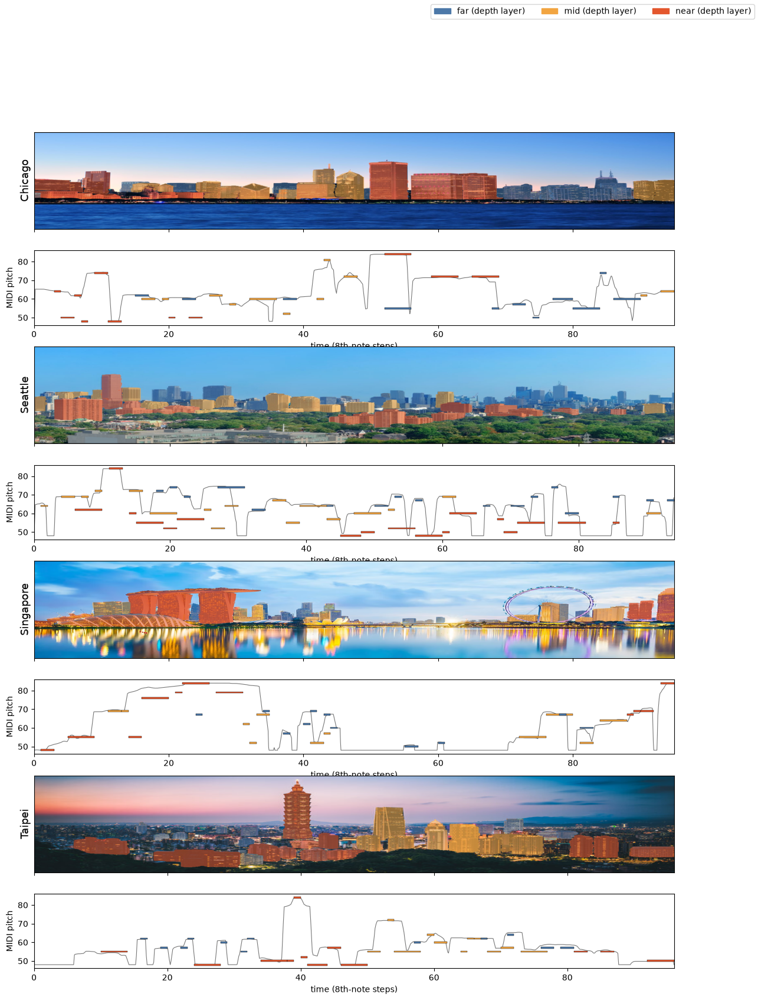

In [8]:
def tint(img, masks, kept, dropped):
    out = np.asarray(img).astype(float)
    for f in dropped:
        out[masks[f["i"]]] = .5 * out[masks[f["i"]]] + .5 * 128
    return out

fig = plt.figure(figsize=(14, 4.6 * len(CITIES)))
gs = fig.add_gridspec(2 * len(CITIES), 1, height_ratios=[1.3, 1] * len(CITIES), hspace=0.25)
for r, name in enumerate(CITIES):
    R = results[name]; H, W = R["masks"].shape[1:]
    steps = max(n["onset"] + n["dur"] for n in R["notes"])
    img = tint(R["img"], R["masks"], R["kept"], R["dropped"])
    for n in R["notes"]:
        m = R["masks"][n["mask"]]
        c = np.array(plt.matplotlib.colors.to_rgb(LAYERS[n["layer"]]["color"])) * 255
        img[m] = .45 * img[m] + .55 * c
    a = fig.add_subplot(gs[2 * r]); b = fig.add_subplot(gs[2 * r + 1], sharex=a)
    a.imshow(img.astype(np.uint8), extent=(0, N_STEPS, H, 0), aspect="auto")
    a.set_ylabel(name.title(), fontsize=13); a.set_yticks([])
    plt.setp(a.get_xticklabels(), visible=False)
    for n in R["notes"]:
        b.barh(n["midi"], n["dur"], left=n["onset"], height=.9, color=LAYERS[n["layer"]]["color"], edgecolor="k", lw=.3)
    b.plot(np.linspace(0, N_STEPS, len(R["cols"])), R["cols"], color="#555", lw=.8, alpha=.8, zorder=0)
    b.set_xlim(0, steps); a.set_xlim(0, steps); b.set_ylim(SCALE[0] - 2, SCALE[-1] + 2)
    b.set_ylabel("MIDI pitch"); b.set_xlabel("time (8th-note steps)")
hs = [plt.Rectangle((0, 0), 1, 1, color=v["color"]) for v in LAYERS.values()]
fig.legend(hs, [f'{v["name"]} (depth layer)' for v in LAYERS.values()] + [], loc="upper right", ncol=3)
fig.savefig(OUT / "fig_music.png", dpi=130, bbox_inches="tight")
plt.show()

## Listen: ours vs naive

In [9]:
from IPython.display import Audio, display, HTML
for name in CITIES:
    display(HTML(f"<b>{name.title()}</b>: ours"))
    display(Audio(str(OUT / "music" / f"{name}_ours.wav")))
    display(HTML(f"{name.title()}: naive"))
    display(Audio(str(OUT / "music" / f"{name}_naive.wav")))